In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_symbolic_regression_results(dataset, plot_outliers=True):
    """
    Plots the results of a symbolic regression model against the provided dataset.
    
    Args:
    symbolic_model (function): A symbolic regression model that predicts Gibbs energy given a dataset.
    dataset (pd.DataFrame): A DataFrame containing the features and true Gibbs energy.
    
    Returns:
    None
    """
    # Apply the symbolic regression model to predict Gibbs energy
    # dataset['preds'] = symbolic_model(dataset)

    # Calculate percentage difference between true and predicted values
    dataset['percentage_diff'] = 100 * np.abs(dataset['Gibbs_energy'] - dataset['preds']) / dataset['Gibbs_energy']
    perc_diff = list(dataset['percentage_diff'])

    # Plotting the box plot without outliers
    plt.figure(figsize=(10, 6))
    plt.boxplot(
        dataset['percentage_diff'].dropna(),
        vert=False,
        patch_artist=True,
        showfliers=plot_outliers,  # Hide outliers
        boxprops=dict(facecolor='skyblue', color='blue'),
        whiskerprops=dict(color='blue'),
        capprops=dict(color='blue'),
        medianprops=dict(color='red')
    )
    plt.title("Box Plot of Percentage Differences (Without Outliers)")
    plt.xlabel("Percentage Difference")
    plt.grid(True)
    plt.show()

    # Find highest and lowest percentage differences
    min_index = dataset['percentage_diff'].idxmin()
    max_index = dataset['percentage_diff'].idxmax()

    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = np.percentile(perc_diff, 25)
    Q3 = np.percentile(perc_diff, 75)

    # Calculate IQR (Interquartile Range)
    IQR = Q3 - Q1

    # Determine the bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers = [x for x in perc_diff if (x > upper_bound or x < lower_bound)]
    num_outliers = len(outliers)

    print(f"Number of outliers: {num_outliers}")

    # Get the corresponding rows for min and max percentage differences
    min_row = dataset.loc[min_index]
    max_row = dataset.loc[max_index]

    # Print details for the minimum percentage difference
    print("Minimum percentage difference:")
    print("Index:", min_index)
    print("True Gibbs Energy:", min_row['Gibbs_energy'])
    print("Predicted Gibbs Energy:", min_row['preds'])
    print("Percentage Difference:", min_row['percentage_diff'], "%")

    # Print details for the maximum percentage difference
    print("\nMaximum percentage difference:")
    print("Index:", max_index)
    print("True Gibbs Energy:", max_row['Gibbs_energy'])
    print("Predicted Gibbs Energy:", max_row['preds'])
    print("Percentage Difference:", max_row['percentage_diff'], "%")

    # Plotting true vs predicted Gibbs energy
    ax = dataset.plot(x="Gibbs_energy", y="preds", kind="scatter", color='blue', label='Prediction')
    dataset.plot(x="Gibbs_energy", y="Gibbs_energy", color="red", kind="scatter", ax=ax, label='Ground Truth')

    # Add title and legend
    plt.title("Prediction vs. True Values - Gibbs Energy")
    plt.xlabel("True Gibbs Energy")
    plt.ylabel("Predicted Gibbs Energy")
    plt.legend()

    # Show the plot
    plt.show()

# Example usage:
# def symbolic_model(df):
#     return (-0.95847567096412 * df['Temperature_[K]']
#             - np.sin(-0.23560148 * df['Mass_fraction_Nb'] * np.sin(df['Mass_fraction_Al'])
#                      + 0.23560148 * df['Mass_fraction_Al']
#                      + 0.142045748453794 * df['Mass_fraction_Ti']))

# symbolic_model = 

# df = pd.DataFrame({ ... })  # your dataset here
# plot_symbolic_regression_results(symbolic_model, df)


In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Define available scalers
SCALER_DISPATCH = {
    'standard': StandardScaler,
    'minmax': MinMaxScaler,
    'robust': RobustScaler
}

def scale_dataframe(df, target_col, scaler_type='standard'):
    """
    Scales the features and target in the DataFrame.

    Parameters:
    - df: pd.DataFrame, the DataFrame containing the data.
    - target_col: str, the name of the target column.
    - scaler_type: str, the type of scaler to use ('standard', 'minmax', 'robust').

    Returns:
    - pd.DataFrame: DataFrame with scaled features and target.
    """
    # Check if the specified scaler type is valid
    if scaler_type not in SCALER_DISPATCH:
        raise ValueError(f"Scaler type '{scaler_type}' is not supported. Choose from {list(SCALER_DISPATCH.keys())}.")

    # Separate the features (X) and target (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Initialize the scalers
    feature_scaler = SCALER_DISPATCH[scaler_type]()
    target_scaler = SCALER_DISPATCH[scaler_type]()

    # Scale the features (X)
    X_scaled = feature_scaler.fit_transform(X)

    # Scale the target (y)
    y_2d = np.reshape(y.values, (y.shape[0], 1))
    y_scaled = target_scaler.fit_transform(y_2d).flatten()

    # Create a DataFrame from the scaled features
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

    # Add the scaled target column
    X_scaled_df[target_col] = y_scaled

    return X_scaled_df


In [4]:
import numpy as np
import math

def evaluate_symbolic_expression(df, expression):
    """
    Evaluate a symbolic expression with variables (x0, x1, etc.) mapped to DataFrame columns
    based on their order.

    Parameters:
    - df: pd.DataFrame, the DataFrame containing the data.
    - expression: str, the symbolic expression to evaluate (e.g., '(-x0 + x1)').

    Returns:
    - pd.Series, the result of the evaluated expression.
    """

    # Create a dictionary to map x0, x1, etc. to the DataFrame columns by order
    local_vars = {f'x{i}': df.iloc[:, i] for i in range(df.shape[1])}

    # Evaluate the expression using the local variables
    try:
        result = eval(expression, {"np": np, "math": math}, local_vars)
    except Exception as e:
        raise ValueError(f"Error in evaluating the expression: {e}")

    return result

def extract_best_equation(csv_file_path):
    """
    Extract the best equation based on the lowest MAE from the CSV file, 
    and return the equation with its MSE, MAE, and RMSE.

    Parameters:
    - csv_file_path: str, the path to the CSV file.

    Returns:
    - tuple: (str, float, float, float), the best equation, its MSE, MAE, and RMSE.
    """
    # Load the CSV file into a DataFrame
    df = pd.read_csv(csv_file_path)

    # Find the row with the lowest MAE
    best_row = df.loc[df['MAE'].idxmin()]

    # Extract the equation and its metrics from that row
    best_equation = best_row['Equation']
    best_mse = best_row['MSE']
    best_mae = best_row['MAE']
    best_rmse = best_row['RMSE']
    
    return best_equation, best_mse, best_mae, best_rmse

def calculate_errors_and_std(df, y_true_col, y_pred_col):
    """
    Calculate and print the MAE, RMSE, and MSE with their standard deviations.

    Parameters:
    - df: pd.DataFrame, the DataFrame containing the true and predicted values.
    - y_true_col: str, the name of the column with true values.
    - y_pred_col: str, the name of the column with predicted values.

    Prints the results in a nice format.
    """
    
    # Calculate errors
    errors = df[y_true_col] - df[y_pred_col]
    
    mae = np.mean(np.abs(errors))
    mae_std = np.std(np.abs(errors))
    
    mse = np.mean(errors ** 2)
    mse_std = np.std(errors ** 2)
    
    rmse = np.sqrt(mse)
    rmse_std = np.std(np.sqrt(errors ** 2))
    
    # Print the results in a nice format
    print(f"Mean Absolute Error (MAE): {mae:.5f} ± {mae_std:.5f}")
    print(f"Mean Squared Error (MSE): {mse:.5f} ± {mse_std:.5f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.5f} ± {rmse_std:.5f}")


import pandas as pd

file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all_cr/718_all_cr.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")
    


csv_file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all_cr/symbolic_regression/symbolic_regression_metrics_2.csv'  # Update this path
best_equation, best_mse, best_mae, best_rmse = extract_best_equation(csv_file_path)

# Print the best equation with its metrics
print(f"Best Equation: {best_equation}")
# print(f"MSE: {best_mse}")
# print(f"MAE: {best_mae}")
# print(f"RMSE: {best_rmse}")

df = scale_dataframe(df, 'Gibbs_energy')

preds = evaluate_symbolic_expression(df, best_equation)
df['preds'] = preds

calculate_errors_and_std(df, 'Gibbs_energy', 'preds')

Best Equation: -x0 + (x0*x0*1.3024131 - x1 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866
Mean Absolute Error (MAE): 0.00243 ± 0.00204
Mean Squared Error (MSE): 0.00001 ± 0.00002
Root Mean Squared Error (RMSE): 0.00317 ± 0.00204


/tmp/ipykernel_1053663/1223184437.py:90: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


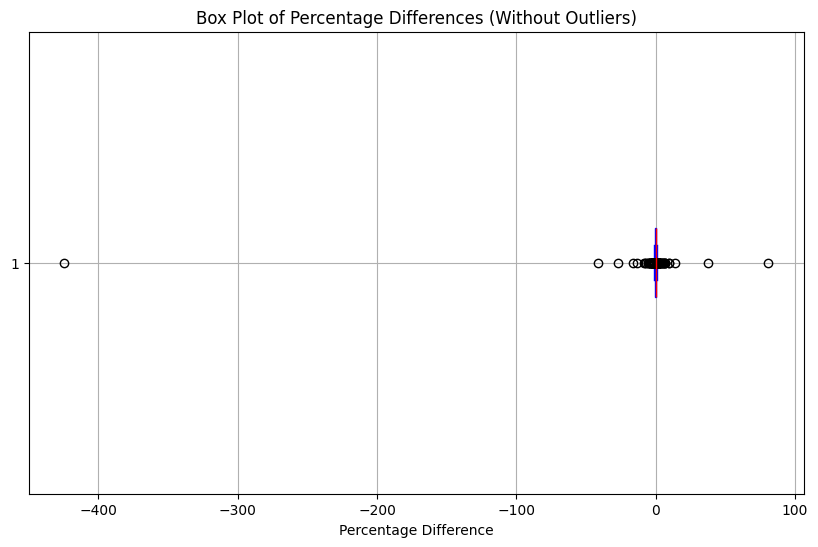

Number of outliers: 109
Minimum percentage difference:
Index: 40
True Gibbs Energy: -0.0013636118076820452
Predicted Gibbs Energy: -0.007156072997620548
Percentage Difference: -424.7881367194157 %

Maximum percentage difference:
Index: 121
True Gibbs Energy: 0.0037420960312761647
Predicted Gibbs Energy: 0.0007133973750741256
Percentage Difference: 80.93588809288691 %


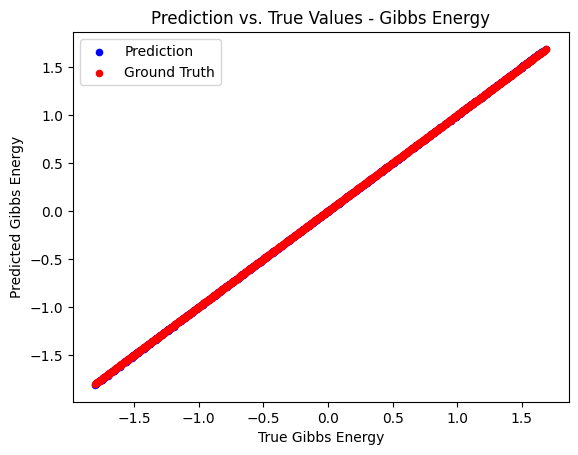

In [5]:
plot_symbolic_regression_results(df, plot_outliers=True)

In [6]:
import numpy as np
import pandas as pd
import sympy as sp
import math

def evaluate_symbolic_expression(df, expression):
    """Evaluate a symbolic expression with variables (x0, x1, etc.) mapped to DataFrame columns based on their order."""
    local_vars = {f'x{i}': df.iloc[:, i] for i in range(df.shape[1])}
    result = eval(expression, {"np": np, "math": math}, local_vars)
    return result

def normalize_weights(weights):
    """Normalize weights so that they sum to 1."""
    total = sum(weights)
    return [w / total for w in weights]

def ensemble_prediction(point, equations, reference_points):
    """
    Ensemble predictions from multiple symbolic regression equations based on the proximity to reference points.
    
    Parameters:
    - point: dict, the query point with feature values.
    - equations: dict, symbolic regression equations for different elements.
    - reference_points: dict, reference points used to derive each equation.
    
    Returns:
    - float, the ensemble prediction of Gibbs energy.
    """
    
    predictions = []
    distances = []
    
    for element, equation in equations.items():
        # Create a DataFrame for the query point
        df = pd.DataFrame([point])
        
        # Evaluate the symbolic regression equation
        prediction = evaluate_symbolic_expression(df, equation)[0]
        
        # Calculate the distance to the reference point
        distance = calculate_distance(point, reference_points[element])
        
        predictions.append(prediction)
        distances.append(distance)
    
    # Calculate weights based on inverse of distances
    weights = [1 / (d + 1e-6) for d in distances]  # Adding a small constant to avoid division by zero
    weights = normalize_weights(weights)
    
    # Calculate the weighted sum of predictions
    ensemble_pred = np.sum(np.array(predictions) * np.array(weights))
    
    return ensemble_pred, weights

# Example equations (replace with actual symbolic regression equations)
symbolic_regression_equations = {
    'Nb': '(-x0 + (x1 + np.log(np.arcsinh(-x1 + np.exp(np.cosh(x0))))/np.log(10))/(-x1 - 3.2844443))/1.0527695',
    'Al': '-1.0333887**(x0**2 - 1*1.0025795) - x0 + (1.029377**0.84277356)**x1',
    'Ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x1) + 0.031627774',
    # Add other elements...
}

# Example reference points used to derive each equation (replace with actual reference points)
reference_points = {
    'Nb': [0.02, 0.005, 0.01, 0.03, 0.195, 0.53, 0.18, 1000],
    'Al': [0.015, 0.006, 0.012, 0.025, 0.19, 0.52, 0.17, 980],
    'Ti': [0.022, 0.004, 0.013, 0.033, 0.198, 0.525, 0.182, 1020],
    # Add reference points for other elements...
}

# Example query point (replace with actual values)
query_point = {
    'Mass_fraction_Nb': 0.027,
    'Mass_fraction_Al': 0.005,
    'Mass_fraction_Ti': 0.01,
    'Mass_fraction_Mo': 0.03,
    'Mass_fraction_Fe': 0.195,
    'Mass_fraction_Ni': 0.53,
    'Mass_fraction_Cr': 0.18,
    'Temperature_[K]': 1000
}

# Get ensemble prediction
ensemble_pred, weights = ensemble_prediction(query_point, symbolic_regression_equations, reference_points)
print(f"Ensemble Predicted Gibbs Energy: {ensemble_pred}")

# Print weights
print(f"Weights: {weights}")


TypeError: unsupported operand type(s) for -: 'dict' and 'list'

In [10]:
import numpy as np
import pandas as pd
import sympy as sp
import math
from sympy.parsing.sympy_parser import parse_expr

def evaluate_symbolic_expression(df, expression, variables):
    """Evaluate a symbolic expression with variables (x0, x1, etc.) mapped to DataFrame columns based on their order."""
    local_vars = {var: df[var].values[0] for var in variables}
    # print(expression)
    # print(expression)
    # print(parse_expr(expression, transformations="all"))
    expr = sp.sympify(parse_expr(expression, transformations="all"))
    result = expr.evalf(subs=local_vars)
    return result


def normalize_weights(weights):
    """Normalize weights so that they sum to 1."""
    total = sum(weights)
    return [w / total for w in weights]

def compute_gradient(expression, variables, point):
    """Compute the gradient of the expression with respect to each variable at the given point."""
    sym_vars = sp.symbols(variables)
    print(expression)
    expr = sp.sympify(expression)
    gradients = [sp.diff(expr, var).evalf(subs=dict(zip(sym_vars, point))) for var in sym_vars]
    return gradients

def ensemble_prediction_with_gradient(point, equations, reference_points, variables):
    """
    Ensemble predictions from multiple symbolic regression equations based on the proximity to reference points
    and gradient influence.

    Parameters:
    - point: dict, the query point with feature values.
    - equations: dict, symbolic regression equations for different elements.
    - reference_points: dict, reference points used to derive each equation.
    - variables: list, the list of variables used in the symbolic expressions.

    Returns:
    - float, the ensemble prediction of Gibbs energy.
    """
    predictions = []
    distances = []
    gradient_influences = []

    for element, equation in equations.items():
        # Create a DataFrame for the query point
        df = pd.DataFrame([point], columns=variables)

        # Evaluate the symbolic regression equation
        prediction = evaluate_symbolic_expression(df, equation, variables)

        # Calculate the distance to the reference point
        distance = calculate_distance(point, reference_points[element])

        # Compute the gradient of the equation at the reference point
        ref_point_values = [reference_points[element][i] for i in range(len(variables))]
        gradients = compute_gradient(equation, variables, ref_point_values)

        # Compute the gradient influence (assuming some function of the gradient)
        gradient_influence = np.dot(gradients, np.array(list(point.values())) - np.array(ref_point_values))
        
        predictions.append(prediction)
        distances.append(distance)
        gradient_influences.append(gradient_influence)
    
    # Calculate weights based on inverse of distances
    weights = [1 / (d + 1e-6) for d in distances]  # Adding a small constant to avoid division by zero
    weights = normalize_weights(weights)
    
    # Adjust predictions by gradient influence
    adjusted_predictions = np.array(predictions) + np.array(gradient_influences)
    
    # Calculate the weighted sum of adjusted predictions
    ensemble_pred = np.sum(adjusted_predictions * np.array(weights))
    
    return ensemble_pred, weights

# Example symbolic regression equations (replace with actual equations)
symbolic_regression_equations = {
    'Nb': '(-x0 + (x1 + log(arcsinh(-x1 + exp(cosh(x0))))/log(10))/(-x1 - 3.2844443))/1.0527695',
    'Al': '-1.0333887**(x0**2 - 1*1.0025795) - x0 + (1.029377**0.84277356)**x1',
    'Ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x1) + 0.031627774',
    # Add other elements...
}

# Example reference points used to derive each equation (replace with actual reference points)
reference_points = {
    'Nb': [0.02, 0.005, 0.01, 0.03, 0.195, 0.53, 0.18, 1000],
    'Al': [0.015, 0.006, 0.012, 0.025, 0.19, 0.52, 0.17, 980],
    'Ti': [0.022, 0.004, 0.013, 0.033, 0.198, 0.525, 0.182, 1020],
    # Add reference points for other elements...
}

# Example query point (replace with actual values)
query_point = {
    'x0': 0.02,
    'x1': 0.005,
    'x2': 0.01,
    'x3': 0.03,
    'x4': 0.195,
    'x5': 0.53,
    'x6': 0.18,
    'x7': 1000
}

# Variable names for the equations (replace with actual variable names)
variable_names = ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7']

# Get ensemble prediction
ensemble_pred, weights = ensemble_prediction_with_gradient(query_point, symbolic_regression_equations, reference_points, variable_names)
print(f"Ensemble Predicted Gibbs Energy: {ensemble_pred}")

# Print weights
print(f"Weights: {weights}")


TypeError: unsupported operand type(s) for -: 'dict' and 'list'

In [11]:
def scale_dataframe(df, target_col, scaler_type='standard'):
    """
    Scales the features and target in the DataFrame.

    Parameters:
    - df: pd.DataFrame, the DataFrame containing the data.
    - target_col: str, the name of the target column.
    - scaler_type: str, the type of scaler to use ('standard', 'minmax', 'robust').

    Returns:
    - pd.DataFrame: DataFrame with scaled features and target.
    """
    # Check if the specified scaler type is valid
    if scaler_type not in SCALER_DISPATCH:
        raise ValueError(f"Scaler type '{scaler_type}' is not supported. Choose from {list(SCALER_DISPATCH.keys())}.")

    # Separate the features (X) and target (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Initialize the scalers
    feature_scaler = SCALER_DISPATCH[scaler_type]()
    target_scaler = SCALER_DISPATCH[scaler_type]()

    # Select only numeric columns for scaling
    numeric_features = X.select_dtypes(include=[np.number])

    # Scale the numeric features
    X_scaled_numeric = feature_scaler.fit_transform(numeric_features)

    # Convert scaled numeric features back to DataFrame
    X_scaled_numeric_df = pd.DataFrame(X_scaled_numeric, columns=numeric_features.columns, index=X.index)

    # Concatenate scaled numeric features with non-numeric features
    non_numeric_features = X.drop(columns=numeric_features.columns)
    X_scaled_df = pd.concat([X_scaled_numeric_df, non_numeric_features], axis=1)

    # Scale the target (y)
    y_2d = np.reshape(y.values, (y.shape[0], 1))
    y_scaled = target_scaler.fit_transform(y_2d).flatten()

    # Add the scaled target column
    X_scaled_df[target_col] = y_scaled

    return X_scaled_df

In [12]:
import pandas as pd

file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")


# df = df.drop('temp_class', axis=1)
# print(df)
df = df.drop('Mass_fraction_Ni', axis=1) # because it didn't change in the dataset

df = scale_dataframe(df, 'Gibbs_energy')

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(df) * 0.8)

# Randomly sample 80% of the rows
reference_df = df.sample(n=sample_size, random_state=42)

reference_columns = [
    'Mass_fraction_Nb', 'Mass_fraction_Al', 'Mass_fraction_Ti', 
    'Mass_fraction_Mo', 'Mass_fraction_Fe', 
    'Mass_fraction_Cr', 'Temperature_[K]', 'Gibbs_energy'
]

# Create the reference_points DataFrame with only the necessary columns
reference_points_df = reference_df[reference_columns]

# Extract the 'temp_class' to use as keys for the reference points
temp_class_series = reference_df['temp_class']

# Initialize a dictionary to store reference points by 'temp_class'
reference_points = {}

# print(reference_points_df)

# Iterate over the unique temp classes
for temp_class in temp_class_series.unique():
    # Filter the DataFrame for the current temp class
    temp_class_df = reference_points_df[temp_class_series == temp_class]
    
    # Convert the DataFrame to a list of lists and store in the dictionary
    reference_points[temp_class.capitalize()] = temp_class_df[['Temperature_[K]', f'Mass_fraction_{temp_class.capitalize()}', 'Gibbs_energy']].values.tolist()

# Output the reference_points dictionary
# print(reference_points)


/tmp/ipykernel_1053663/4014258710.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [14]:
columns = ['Temperature_[K]'] + [col for col in reference_points_df.columns if col != 'Temperature_[K]']

# Reorder the columns in the DataFrame
reference_points_df = reference_points_df[columns]

In [15]:
# ref points are in [temperature, mass_fraction, gibbs_energy]

In [16]:
reference_points

{'Al': [[-0.2566196768304905, 1.7852761865658142, -0.17222126834033644],
  [0.8981688689067167, 2.3375362013993435, -1.398798985717439],
  [-0.9837087611835468, 1.7852761865658142, 0.4991687234956732],
  [0.7270890843530563, 4.546576260733459, -1.4239255602318264],
  [-1.026478707321962, 3.4420562310664016, 0.2921389508497561],
  [0.1710797845536603, 5.098836275566988, -0.9011960004132504],
  [-1.4114082225676976, 0.680756156898756, 1.1496570137054323],
  [-1.2403284380140374, 5.098836275566988, 0.3778333312513633],
  [0.3421595691073206, 1.7852761865658142, -0.7504805578357084],
  [1.1547885457372071, -0.4237638727683021, -0.922934227751442],
  [0.9409388150451317, 1.7852761865658142, -1.350482035075062],
  [-0.9837087611835468, 2.889796216232872, 0.3175273521913948],
  [1.4969481148445276, -0.4237638727683021, -1.2831551366389629],
  [0.8126289766298864, 4.546576260733459, -1.5084142170928134],
  [-0.08553989227683015, 0.12849614206522697, 0.09977764116115276],
  [-0.8126289766298864

In [17]:
COLUMN_TO_VAR ={
        'Temperature_[K]': 'x0',
        'Mass_fraction_Nb': 'x1',
        'Mass_fraction_Al': 'x2',
        'Mass_fraction_Ti': 'x3',	
        "Mass_fraction_Mo": 'x4',	
        'Mass_fraction_Fe': 'x5',	
        'Mass_fraction_Cr': 'x6',	
    }

In [18]:
import numpy as np
import pandas as pd
import math

def evaluate_expression(expression, point):
    """Evaluate a numerical expression with given point values."""
    # Replace variable names with their values
    
    # print(point)
    # print(expression)
    
    for var, value in point.items():
        expression = expression.replace(var, str(value))
        # print(expression)
    # print(expression)
    return eval(expression)

# def calculate_distance(point, ref_point, element):
#     """Calculate the Euclidean distance between the query point and a reference point."""
#     # Extract temperature and mass fraction from the point
#     # print(point)
#     # print(ref_point)
#     point_values = np.array([
#         point[COLUMN_TO_VAR['Temperature_[K]']], 
#         point[COLUMN_TO_VAR[f'Mass_fraction_{element}']]
#     ])
    
#     # print(ref_point)
    
#     # Extract temperature and mass fraction from the reference point
#     ref_point_values = np.array(ref_point[:2])  # Only temperature and mass fraction for distance
    
#     # Compute Euclidean distance
#     return np.sqrt(np.sum((point_values - ref_point_values) ** 2))

def normalize_weights(weights):
    """Normalize weights so that they sum to 1."""
    total = sum(weights)
    return [w / total for w in weights]

def compute_numerical_gradient(expression, point, variables, closest_points, epsilon=1e-6):
    """Compute the numerical gradient of the expression with respect to each variable using closest points."""
    gradients = []
    
    for var in variables:
        point = {key: point[key] for key in point if key in variables}
        
        point_plus = point.copy()
        point_minus = point.copy()
        
        point_plus[var] += epsilon
        point_minus[var] -= epsilon
        
        # print(point_plus)
        # print(point_minus)
        # print(expression)
        # Compute function values at perturbed points
        f_plus_values = []
        f_minus_values = []
        
        # print(closest_points)
        
        for p in closest_points:
            # `p` is a list [temperature, mass_fraction, gibbs_energy]
            temp, mass_frac, _ = p
            
            # print(point_plus)
            
            # print({**point_plus, **{var: temp}})
            
            # print(var)
            
            # Compute f_plus and f_minus using point_plus and point_minus
            # Note that point[var] should be a single numerical value, not a list
            f_plus = evaluate_expression(expression, {**point_plus, **{var: temp, 'mass_fraction': mass_frac}})
            f_minus = evaluate_expression(expression, {**point_minus, **{var: temp, 'mass_fraction': mass_frac}})
            
            f_plus_values.append(f_plus)
            f_minus_values.append(f_minus)
        
        
        
        f_plus_mean = np.mean(f_plus_values)
        f_minus_mean = np.mean(f_minus_values)
        
        gradient = (f_plus_mean - f_minus_mean) / (2 * epsilon)
        gradients.append(gradient)
    
    return gradients


def get_closest_points(query_point, ref_points, n, element):
    """
    Find the closest `n` reference points to the query point.
    
    Parameters:
    - query_point: dict, the query point with feature values.
    - ref_points: list of lists, each list contains [temperature, mass_fraction, gibbs_energy].
    - n: int, number of closest points to return.
    
    Returns:
    - list of lists: the closest `n` reference points.
    """
    
    distances = [calculate_distance(query_point, ref_point[:2], element) for ref_point in ref_points]
    closest_indices = np.argsort(distances)[:n]
    
    
    return [ref_points[i] for i in closest_indices]




def ensemble_prediction_with_gradient(point, equations, reference_points, variables, n_closest=3):
    """
    Ensemble predictions from multiple symbolic regression equations based on the proximity to reference points
    and gradient influence using numerical methods.

    Parameters:
    - point: dict, the query point with feature values.
    - equations: dict, symbolic regression equations for different elements.
    - reference_points: dict, reference points used to derive each equation.
    - variables: dict, dictionary with element as key and list of variables for that element.
    - n_closest: int, number of closest reference points to use for gradient calculation.

    Returns:
    - float, the ensemble prediction of Gibbs energy.
    """
    predictions = []
    distances = []
    gradient_influences = []

    for element, equation in equations.items():
        ref_points = reference_points[element]
        
        relevant_vars = [COLUMN_TO_VAR[f'Mass_fraction_{element}'], COLUMN_TO_VAR['Temperature_[K]']]
        
        current_element_point = point.copy()
        current_element_point = {key: current_element_point[key] for key in current_element_point if key in variables}
        
        
        # Get the closest n reference points
        closest_points = get_closest_points(point, ref_points, n_closest, element)
        
        # Evaluate the equation at the query point
        prediction = evaluate_expression(equation, point)
        
        # Calculate the distance to the closest reference points
        distance = np.mean([calculate_distance(point, p[:2], element) for p in closest_points])
        
        # Compute the gradient of the equation at the closest points
        # relevant_vars.append()
        
        gradients = compute_numerical_gradient(equation, point, relevant_vars, closest_points)
        
        # print(relevant_vars)
        
        # Extract only the relevant values from the point
        relevant_point_values = np.array([point[var] for var in relevant_vars])
        
        # Compute the gradient influence
        gradient_influence = np.dot(gradients, relevant_point_values - np.mean(np.array([p[:2] for p in closest_points]), axis=0))
        
        predictions.append(prediction)
        distances.append(distance)
        gradient_influences.append(gradient_influence)
    
    # Calculate weights based on the inverse of distances
    weights = [1 / (d + 1e-6) for d in distances]
    weights = normalize_weights(weights)
    
    # Adjust predictions by gradient influence
    adjusted_predictions = np.array(predictions) + np.array(gradient_influences)
    
    # Calculate the weighted sum of adjusted predictions
    ensemble_pred = np.sum(adjusted_predictions * np.array(weights))
    
    return ensemble_pred, weights


# Example symbolic regression equations (replace with actual equations)
symbolic_regression_equations = {
    'Nb': '0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104))',
    'Al': '1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786)',
    'Ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774',
    'Mo': '-x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675',
    'Fe': '-x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575)',
    'Cr': '-x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866',
    # Add other elements...
}

# Example reference points used to derive each equation (replace with actual reference points)
# reference_points = {
#     'Nb': [0.02, 0.005, 0.01, 0.03, 0.195, 0.53, 0.18, 1000],
#     'Al': [0.015, 0.006, 0.012, 0.025, 0.19, 0.52, 0.17, 980],
#     'Ti': [0.022, 0.004, 0.013, 0.033, 0.198, 0.525, 0.182, 1020],
#     # Add reference points for other elements...
# }

# Reference point: (temperature, mass_fraction, gibbs_energy)

# Example query point (replace with actual values)
query_point = reference_points_df.iloc[0].to_dict()

def transform_point(point, column_to_var):
    transformed = {column_to_var[key]: float(value) for key, value in point.items() if key in column_to_var}
    return transformed

# Get the transformed point
transformed_point = transform_point(query_point, COLUMN_TO_VAR)
# print(transformed_point)

# Variable names for the equations (replace with actual variable names)
variable_names = ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7']

# query_point = {
#     'x0': 0.02,
#     'x1': 0.005,
#     'x2': 0.01,
#     'x3': 0.03,
#     'x4': 0.195,
#     'x5': 0.53,
#     'x6': 0.18,
#     'x7': 1000
# }


# Get ensemble prediction
ensemble_pred, weights = ensemble_prediction_with_gradient(transformed_point, symbolic_regression_equations, reference_points, variable_names)

print(f"Ensemble Predicted Gibbs Energy: {ensemble_pred}")

# Print weights
print(f"Weights: {weights}")


TypeError: calculate_distance() takes 2 positional arguments but 3 were given

In [ ]:
import numpy as np
import pandas as pd


def ensemble_prediction(point, equations, reference_points):
    """
    Ensemble predictions from multiple symbolic regression equations based on the proximity to the closest reference point.

    Parameters:
    - point: dict, the query point with feature values.
    - equations: dict, symbolic regression equations for different elements.
    - reference_points: dict, reference points used to derive each equation.

    Returns:
    - float, the ensemble prediction of Gibbs energy.
    """
    
    predictions = []
    distances = []
    
    for element, equation in equations.items():
        # Get the reference points for the current element
        ref_points = reference_points[element]
        
        # Find the closest reference point
        closest_point = get_closest_points(point, ref_points, n=1, element=element)[0]
        
        # Create a DataFrame for the query point
        df = pd.DataFrame([point])
        
        # Evaluate the symbolic regression equation
        prediction = evaluate_symbolic_expression(df, equation)[0]
        
        # Calculate the distance to the closest reference point
        distance = calculate_distance(point, closest_point[:2], element)
        
        predictions.append(prediction)
        distances.append(distance)
    
    # Calculate weights based on the inverse of distances
    weights = [1 / (d + 1e-6) for d in distances]  # Adding a small constant to avoid division by zero
    weights = normalize_weights(weights)
    
    # Calculate the weighted sum of predictions
    ensemble_pred = np.sum(np.array(predictions) * np.array(weights))
    
    return ensemble_pred, weights

# print(reference_points)


ensemble_pred, weights = ensemble_prediction(transformed_point, symbolic_regression_equations, reference_points)
print(f"Ensemble Predicted Gibbs Energy: {ensemble_pred}")

# Print weights
print(f"Weights: {weights}")


Ensemble Predicted Gibbs Energy: 0.21190455621409585
Weights: [0.1999999155870873, 0.1999999155870873, 0.1999999155870873, 0.1999999155870873, 4.2206456361964334e-07, 0.1999999155870873]


In [ ]:
reference_points_df.iloc[0].to_dict()

{'Temperature_[K]': -0.2566196768304905,
 'Mass_fraction_Nb': -0.3843530573929038,
 'Mass_fraction_Al': 1.7852761865658142,
 'Mass_fraction_Ti': -0.40870238953039656,
 'Mass_fraction_Mo': -0.367396684209307,
 'Mass_fraction_Fe': -0.051608509537268456,
 'Mass_fraction_Cr': -0.17921157418305536,
 'Gibbs_energy': -0.17222126834033644}

In [ ]:
extract_best_equation('/home/couchbucks/Documents/saketh/regression/regression/718_all_nb/symbolic_regression/symbolic_regression_metrics_2.csv')

('0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104))',
 1.4724605822501626e-05,
 0.002848781733862,
 0.0038372654094422)

In [19]:
from dataclasses import dataclass
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Define the dataclass
@dataclass
class DataPoint:
    '''
    Point is in the format: 
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    '''
    point: tuple
    index: int
    temp_class: str
    gibbs_energy: float = None

# Load the file
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")

# Define the column mapping
COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    'temp_class': 'x8'
}

# Scaling the dataframe
def scale_dataframe(df, column_to_scale):
    scaler = StandardScaler()
    df[column_to_scale] = scaler.fit_transform(df[[column_to_scale]])
    return df

df = scale_dataframe(df, 'Gibbs_energy')

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(df) * 0.8)

# Randomly sample 80% of the rows
reference_df = df.sample(n=sample_size, random_state=42)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni'
]

# Rename columns and reorder
reference_df = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# Create a list of DataPoint instances
ref_data_points = []
for idx, row in reference_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    ref_data_points.append(DataPoint(point=point, index=idx, temp_class=temp_class))

# Output the created DataPoint objects for verification
# for data_point in data_points:
#     print(data_point)




# reference_columns = [
#     'Mass_fraction_Nb', 'Mass_fraction_Al', 'Mass_fraction_Ti', 
#     'Mass_fraction_Mo', 'Mass_fraction_Fe', 
#     'Mass_fraction_Cr', 'Temperature_[K]', 'Gibbs_energy'
# ]

# # Create the reference_points DataFrame with only the necessary columns
# reference_points_df = reference_df[reference_columns]

# # Extract the 'temp_class' to use as keys for the reference points
# temp_class_series = reference_df['temp_class']

# # Initialize a dictionary to store reference points by 'temp_class'
# reference_points = {}

# # print(reference_points_df)

# # Iterate over the unique temp classes
# for temp_class in temp_class_series.unique():
#     # Filter the DataFrame for the current temp class
#     temp_class_df = reference_points_df[temp_class_series == temp_class]
    
#     # Convert the DataFrame to a list of lists and store in the dictionary
#     reference_points[temp_class.capitalize()] = temp_class_df[['Temperature_[K]', f'Mass_fraction_{temp_class.capitalize()}', 'Gibbs_energy']].values.tolist()

# # Output the reference_points dictionary
# # print(reference_points)


/tmp/ipykernel_1053663/4074342751.py:30: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [ ]:
data_points[0]

DataPoint(point=(1340.0, 0.05, 0.08, 0.01, 0.03, 0.195, 0.18, 0.53), index=2464, temp_class='al')

In [20]:
# Load the file
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")

# Define the column mapping
COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    'temp_class': 'x8'
}

# Scaling the dataframe
def scale_dataframe(df, column_to_scale):
    scaler = StandardScaler()
    df[column_to_scale] = scaler.fit_transform(df[[column_to_scale]])
    return df

df = scale_dataframe(df, 'Gibbs_energy')

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(df) * 0.8)

# Randomly sample 80% of the rows
reference_df = df.sample(n=sample_size, random_state=42)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni'
]

# Rename columns and reorder
reference_df = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# Create a list of DataPoint instances
ref_data_points = []
for idx, row in reference_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    ref_data_points.append(DataPoint(point=point, index=idx, temp_class=temp_class))


sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = df.drop(sampled_indices)

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

# Create a list of DataPoint instances for the remaining 20%
remaining_data_points = []
for idx, row in remaining_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    remaining_data_points.append(DataPoint(point=point, index=idx, temp_class=temp_class))

/tmp/ipykernel_1053663/35766891.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [21]:


def normalize_weights(weights):
    """Normalize weights so that they sum to 1."""
    total = sum(weights)
    return [w / total for w in weights]

def compute_numerical_gradient(expression, point, variables, closest_points, epsilon=1e-6):
    """Compute the numerical gradient of the expression with respect to each variable using closest points."""
    gradients = []
    
    for var in variables:
        point = {key: point[key] for key in point if key in variables}
        
        point_plus = point.copy()
        point_minus = point.copy()
        
        point_plus[var] += epsilon
        point_minus[var] -= epsilon
        
        # print(point_plus)
        # print(point_minus)
        # print(expression)
        # Compute function values at perturbed points
        f_plus_values = []
        f_minus_values = []
        
        # print(closest_points)
        
        for p in closest_points:
            # `p` is a list [temperature, mass_fraction, gibbs_energy]
            temp, mass_frac, _ = p
            
            # print(point_plus)
            
            # print({**point_plus, **{var: temp}})
            
            # print(var)
            
            # Compute f_plus and f_minus using point_plus and point_minus
            # Note that point[var] should be a single numerical value, not a list
            f_plus = evaluate_expression(expression, {**point_plus, **{var: temp, 'mass_fraction': mass_frac}})
            f_minus = evaluate_expression(expression, {**point_minus, **{var: temp, 'mass_fraction': mass_frac}})
            
            f_plus_values.append(f_plus)
            f_minus_values.append(f_minus)
        
        
        
        f_plus_mean = np.mean(f_plus_values)
        f_minus_mean = np.mean(f_minus_values)
        
        gradient = (f_plus_mean - f_minus_mean) / (2 * epsilon)
        gradients.append(gradient)
    
    return gradients



In [22]:
query

NameError: name 'query' is not defined

In [23]:
query = DataPoint(
    point = (1008, 0.005671223028396569, 0.00477474491652328, 0.00969053221312119, 0.03097545274716367, 0.19458655163007046, 0.5313244937075174, 0.18856732661091122),
    index=0,
    temp_class='al'
)

In [24]:
all_ref_points = [np.array(x.point) for x in ref_data_points]

In [26]:
import pandas as pd
import numpy as np

# Define the CustomStandardScaler class as previously mentioned
class CustomStandardScaler:
    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X):
        """Compute the mean and standard deviation of the features."""
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0)
        return self

    def transform(self, X):
        """Scale features by removing the mean and scaling to unit variance."""
        if self.mean_ is None or self.scale_ is None:
            raise RuntimeError("You must fit the scaler before transforming data.")
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        """Fit to the data and then transform it."""
        return self.fit(X).transform(X)

def get_fitted_scaler_from_csv(file_path, target_col, scaler_type='standard'):
    """
    Reads a CSV file, scales the features, and returns a fitted CustomStandardScaler.

    Parameters:
    - file_path: str, the path to the CSV file.
    - target_col: str, the name of the target column.
    - scaler_type: str, the type of scaler to use ('standard').

    Returns:
    - CustomStandardScaler: Fitted scaler object.
    - pd.DataFrame: DataFrame with scaled features and target.
    """
    # Load the CSV file into a DataFrame
    if file_path.endswith('.xlsx'):
        df = pd.read_excel(file_path)
    elif file_path.endswith('.txt') or file_path.endswith('.csv'):
        df = pd.read_csv(file_path, delim_whitespace=True)
    else:
        print("Unsupported file format. Please use .txt or .xlsx files.")
        return

    # Initialize the appropriate scaler
    if scaler_type == 'standard':
        feature_scaler = CustomStandardScaler()
    else:
        raise ValueError(f"Scaler type '{scaler_type}' is not supported. Choose 'standard'.")

    # Separate the features (X) and target (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Select only numeric columns for scaling
    numeric_features = X.select_dtypes(include=[np.number])

    # Fit the scaler to the numeric features
    feature_scaler.fit(numeric_features)

    # Scale the numeric features
    X_scaled_numeric = feature_scaler.transform(numeric_features)

    # Convert scaled numeric features back to DataFrame
    X_scaled_numeric_df = pd.DataFrame(X_scaled_numeric, columns=numeric_features.columns, index=X.index)

    # Concatenate scaled numeric features with non-numeric features
    non_numeric_features = X.drop(columns=numeric_features.columns)
    X_scaled_df = pd.concat([X_scaled_numeric_df, non_numeric_features], axis=1)

    # Scale the target (y)
    y_2d = np.reshape(y.values, (y.shape[0], 1))
    target_scaler = CustomStandardScaler().fit(y_2d)
    y_scaled = target_scaler.transform(y_2d).flatten()

    # Add the scaled target column
    X_scaled_df[target_col] = y_scaled

    return feature_scaler, X_scaled_df

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col)

# point = query.point

# column_order = [
#     'Temperature_[K]',
#     'Mass_fraction_Nb',
#     'Mass_fraction_Al',
#     'Mass_fraction_Ti',
#     'Mass_fraction_Mo',
#     'Mass_fraction_Fe',
#     'Mass_fraction_Cr',
#     'Mass_fraction_Ni'
# ]

# # Create a DataFrame with the new point
# new_point_df = pd.DataFrame([point], columns=column_order)

# scaled_features = scaler.transform(new_point_df)

# new_order = [
#     'Temperature_[K]',
#     'Mass_fraction_Nb',
#     'Mass_fraction_Al',
#     'Mass_fraction_Ti',
#     'Mass_fraction_Mo',
#     'Mass_fraction_Fe',
#     'Mass_fraction_Cr',
#     'Mass_fraction_Ni'
# ]

# # Rename columns and reorder
# scaled_features = scaled_features[new_order].rename(columns=COLUMN_TO_VAR)

# # Create a list of DataPoint instances
# # ref_data_points = []
# for idx, row in scaled_features.iterrows():
#     point = tuple(row)  # Convert row to tuple
#     temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
#     query = DataPoint(point=point, index=idx, temp_class=temp_class)

/tmp/ipykernel_1053663/3336194426.py:43: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [27]:
symbolic_regression_equations = {
    'nb': '0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104))',
    'al': '1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786)',
    'ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774',
    'mo': '-x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675',
    'fe': '-x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575)',
    'cr': '-x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866',
    # Add other elements...
}

In [28]:
closest_point = get_closest_points(np.array(query.point), ref_data_points, n=1)
ref_equation = symbolic_regression_equations[closest_point[0].temp_class]
ref_equation

TypeError: get_closest_points() missing 1 required positional argument: 'element'

In [29]:
def get_scaled(point: tuple, scaler: CustomStandardScaler, point_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni']):
    
    # Create a DataFrame with the new point
    new_point_df = pd.DataFrame([point], columns=point_order)

    scaled_features = scaler.transform(new_point_df)
    
    # Rename columns and reorder
    scaled_features = scaled_features[new_order].rename(columns=COLUMN_TO_VAR)


    # Create a list of DataPoint instances
    # ref_data_points = []
    for idx, row in scaled_features.iterrows():
        return tuple(row)  # Convert row to tuple
        # temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
        # query = DataPoint(point=point, index=idx, temp_class=temp_class)
        
    # return query

In [31]:
import numpy as np
import math

def clean_query_point(query_point):
    # Convert the tuple to a list
    point_list = list(query_point)
    
    # Filter out NaN, -inf, and +inf values
    cleaned_point_list = [val for val in point_list if not (np.isnan(val) or np.isinf(val))]
    
    # Convert the cleaned list back to a tuple
    cleaned_point_tuple = tuple(cleaned_point_list)
    
    return cleaned_point_tuple

def compute_numerical_gradient(expression, point, variables, epsilon=1e-5):
    """Compute the numerical gradient of the expression with respect to each variable."""
    gradients = []
    for var in variables:
        point_plus = point.copy()
        point_minus = point.copy()
        
        point_plus[var] += epsilon
        point_minus[var] -= epsilon
        
        
        
        f_plus = evaluate_expression(expression, point_plus)
        f_minus = evaluate_expression(expression, point_minus)
        
        gradient = (f_plus - f_minus) / (2 * epsilon)
        gradients.append(gradient)
    
    return gradients



def weighted_predict_with_gradients(query_point, closest_points, ref_equations, n=1):
    """
    Predict the Gibbs energy using the weighted gradient of the closest reference points.

    Parameters:
    - query_point: tuple, the query point with features.
    - closest_points: list of DataPoint, the closest reference points.
    - ref_equations: dict, symbolic regression equations for different temp_classes.
    - n: int, number of closest points to use for prediction.

    Returns:
    - float, the predicted Gibbs energy.
    """
    query_point = clean_query_point(query_point)
    
    # Define the variable names
    var_names = ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']
    
    # Calculate distances and weights
    distances = np.array([calculate_distance(query_point, point.point) for point in closest_points[:n]])
    weights = 1 / (distances + 1e-6)  # Avoid division by zero
    
    # Normalize weights
    weights /= weights.sum()
    
    print(weights)
    
    # Compute weighted gradients
    weighted_gradients = np.zeros(len(var_names))
    
    for i, point in enumerate(closest_points[:n]):
        # point.point = clean_query_point(point.point)
        
        point_dict = {var_names[j]: point.point[j] for j in range(len(var_names))}
        
        
        # Compute the gradient at this point
        gradients = compute_numerical_gradient(ref_equations[point.temp_class], point_dict, var_names, epsilon=1e-3)
        
        
        # Accumulate weighted gradients
        weighted_gradients += weights[i] * np.array(gradients)
    
    # Prepare query point dictionary
    query_point_dict = {var_names[i]: query_point[i] for i in range(len(query_point))}
    
    # Compute the weighted gradient influence
    weighted_gradient_influence = np.dot(weighted_gradients, np.array(query_point) - np.array(closest_points[0].point))
    
    # Evaluate the equation at the closest point
    closest_point_dict = {var_names[i]: closest_points[0].point[i] for i in range(len(var_names))}
    prediction_at_closest = evaluate_expression(ref_equations[closest_points[0].temp_class], closest_point_dict)
    
    # Adjust the prediction based on weighted gradient influence
    adjusted_prediction = prediction_at_closest + weighted_gradient_influence
    
    return adjusted_prediction

# Example usage
query_point = query.point
scaled_query = np.array(clean_query_point(get_scaled(query_point, scaler)))

closest_points = get_closest_points(np.array(query_point), ref_data_points, n=5)
# print(closest_point)
scaled_ref_points = []
for x in closest_points:
    cleaned = clean_query_point(get_scaled(x.point, scaler))
    scaled_ref_points.append(DataPoint(point = np.array(cleaned), index = -1, temp_class=closest_point.temp_class))

# print(scaled_ref_points)

# print(scaled_ref_point)

symbolic_regression_equations = {
    'nb': '0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104))',
    'al': '1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786)',
    'ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774',
    'mo': '-x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675',
    'fe': '-x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575)',
    'cr': '-x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866',
    # Add other elements...
}

ref_equation = symbolic_regression_equations[closest_point.temp_class]
# ref_equation = symbolic_regression_equations[closest_point.temp_class]

predicted_gibbs_energy = weighted_predict_with_gradients(scaled_query, scaled_ref_points, symbolic_regression_equations, n=1)
print(f"Predicted Gibbs Energy: {predicted_gibbs_energy}")


TypeError: get_closest_points() missing 1 required positional argument: 'element'

In [32]:
# Load the file
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")

# Define the column mapping
COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    'temp_class': 'x8'
}

# Scaling the dataframe
def scale_dataframe(df, column_to_scale):
    scaler = StandardScaler()
    df[column_to_scale] = scaler.fit_transform(df[[column_to_scale]])
    return df

df = scale_dataframe(df, 'Gibbs_energy')

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(df) * 0.8)

# Randomly sample 80% of the rows
reference_df = df.sample(n=sample_size, random_state=42)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni'
]

# Rename columns and reorder
reference_df = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# Create a list of DataPoint instances
ref_data_points = []
for idx, row in reference_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    ref_data_points.append(DataPoint(point=point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))


sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = df.drop(sampled_indices)

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

# Create a list of DataPoint instances for the remaining 20%
remaining_data_points = []
for idx, row in remaining_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    remaining_data_points.append(DataPoint(point=point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))

/tmp/ipykernel_1053663/3374036954.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [ ]:
ref_data_points

In [ ]:
import numpy as np
import sympy as sp

def symbolic_gradient(expression, variables):
    """Compute the symbolic gradient of the expression with respect to each variable."""
    return [sp.diff(expression, var) for var in variables]

def predict_with_directional_derivative(query_point, closest_points, ref_equation, variables):
    """
    Predict the Gibbs energy using the directional derivative method.
    
    Parameters:
    - query_point: tuple, the query point with features.
    - closest_points: list of DataPoints, closest reference points.
    - ref_equation: str, the symbolic regression equation.
    - variables: list of sympy symbols representing the variables.

    Returns:
    - float, the predicted Gibbs energy.
    """
    
    # Convert the query point and closest points to numpy arrays
    query_point = np.array(query_point)
    closest_point = np.array(closest_points[0].point)
    # print(query_point.shape)
    # print(closest_point.shape)
    
    # Compute the symbolic gradient
    gradient_exprs = symbolic_gradient(ref_equation, variables)
    
    # print(gradient_exprs)
    # Evaluate the gradient at the closest point
    point_dict = {variables[i]: closest_point[i] for i in range(len(variables))}
    # print(point_dict)
    
    gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    # print(gradient_at_closest)
    
    # Compute the directional derivative
    direction = query_point - closest_point
    direction_unit_vector = direction / np.linalg.norm(direction)
    
    # print(direction_unit_vector.shape)
    # print(gradient_at_closest.shape)
    
    directional_derivative = np.dot(gradient_at_closest, direction_unit_vector)
    
    # Evaluate the equation at the closest point
    prediction_at_closest = ref_equation.evalf(subs=point_dict)
    
    # Adjust the prediction based on the directional derivative and the distance
    distance = calculate_distance(query_point, closest_point)
    adjusted_prediction = prediction_at_closest + directional_derivative * distance
    
    return adjusted_prediction

# Example usage
query_point = (1008, -0.00567, 0.00477, 0.00969, 0.03097, 0.19458, 0.53132, 0.0)# Example usage
# query_point = query.point
# print(scaler.mean_)

print(query_point)

scaled_query = np.array(clean_query_point(get_scaled(query_point, scaler)))

closest_points = get_closest_points(np.array(query_point), ref_data_points, n=5)
# print(closest_point)
scaled_ref_points = []
for x in closest_points:
    cleaned = clean_query_point(get_scaled(x.point, scaler))
    scaled_ref_points.append(DataPoint(point = np.array(cleaned), index = -1, temp_class=closest_point.temp_class))

print(scaled_ref_points)
print(scaled_query)

# print(scaled_ref_point)

symbolic_regression_equations = {
    'nb': '0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104))',
    'al': '1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786)',
    'ti': '-x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774',
    'mo': '-x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675',
    'fe': '-x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575)',
    'cr': '-x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866',
    # Add other elements...
}

# Define the sympy symbols for the variables
x0, x1, x2, x3, x4, x5, x6, x7 = sp.symbols('x0 x1 x2 x3 x4 x5 x6 x7')
variables = [x0, x1, x2, x3, x4, x5, x6, x7]

# Example symbolic regression equation (as an expression in sympy)
# Replace this with the actual regression equation.
ref_equation = x0*x1 + x2**2 - x3*x4 + sp.sin(x5) + sp.log(x6 + 1)

# Find the closest points
# closest_points = get_closest_points(np.array(query_point), ref_data_points, n=1)

# Predict Gibbs energy
predicted_gibbs_energy = predict_with_directional_derivative(query_point, closest_points, ref_equation, variables)
print(f"Predicted Gibbs Energy: {predicted_gibbs_energy}")


(1008, -0.00567, 0.00477, 0.00969, 0.03097, 0.19458, 0.53132, 0.0)
[DataPoint(point=array([-1.6680279 , -0.38435306, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851,  5.57999674]), index=-1, temp_class='cr', gibbs_energy=None), DataPoint(point=array([-1.6680279 , -0.38435306, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851,  4.7572527 ]), index=-1, temp_class='cr', gibbs_energy=None), DataPoint(point=array([-1.6680279 , -0.38435306, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851,  1.46627652]), index=-1, temp_class='cr', gibbs_energy=None), DataPoint(point=array([-1.6680279 , -1.37972892, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851, -0.17921157]), index=-1, temp_class='cr', gibbs_energy=None), DataPoint(point=array([-1.6680279 , -1.18065375, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851, -0.17921157]), index=-1, temp_class='cr', gibbs_energy=None)]
[-1.67658189 -1.49260455 -0.29204986 -0.41547301 -0.34291107 -0.09141275
 28.72543

In [33]:
import numpy as np
import sympy as sp
import numba as nb

def calculate_distance(point, ref_point):
    """Calculate the Euclidean distance between the query point and a reference point."""

    # Compute Euclidean distance
    return np.sqrt(np.sum((point - ref_point) ** 2))




@nb.njit('int32[:,::1](float64[:,::1])', parallel=True)
def fastSort(a):
    b = np.empty(a.shape, dtype=np.int32)
    for i in nb.prange(a.shape[0]):
        b[i,:] = np.argsort(a[i,:])
    return b

def get_closest_points(query_point, ref_data_points, n):
    """
    Find the closest `n` reference points to the query point.
    
    Parameters:
    - query_point: dict, the query point with feature values.
    - ref_points: a list of DataPoints objects
    - n: int, number of closest points to return.
    
    Returns:
    - list of lists: the closest `n` reference points.
    """
    
    ref_points = [np.array(x.point) for x in ref_data_points]
    
    distances = []
    counter = 0
    
    # print('start')
    
    for ref_point in ref_points:
        try:
            distance = calculate_distance(query_point, ref_point)
            distances.append(distances)
        except Exception as e:
            counter += 1
            pass # this does some weird thing where the ref_points have only 7 features instead of 8. there were only 3 points like that, so Im just passing
            
    # print('end')
    
    print(counter)
    
    # try:
    #     distances = [ for ref_point in ref_points]  
    # except:
    #     print(query_point)
    #     print(ref_points)
    #     raise Exception
    
    closest_indices = fastSort(distances)[:n]
    
    # closest_indices = np.argsort(distances)[:n]
    
    return [ref_data_points[i] for i in closest_indices]

def weighted_predict_with_directional_derivatives(query_point, closest_points, ref_equations, variables, n=1):
    """
    Predict the Gibbs energy using the weighted directional derivative of the closest reference points.

    Parameters:
    - query_point: tuple, the query point with features.
    - closest_points: list of DataPoint, the closest reference points.
    - ref_equations: dict, symbolic regression equations for different temp_classes.
    - variables: list of sympy symbols representing the variables.
    - n: int, number of closest points to use for prediction.

    Returns:
    - float, the predicted Gibbs energy.
    """
    # Clean the query point
    query_point = np.array(clean_query_point(query_point))
    
    # Calculate distances and weights
    distances = np.array([calculate_distance(query_point, point.point) for point in closest_points[:n]])
    weights = 1 / (distances + 1e-6)  # Avoid division by zero
    weights /= weights.sum()  # Normalize weights

    # Initialize variables for weighted gradients and predictions
    weighted_directional_derivative = 0
    weighted_prediction_at_closest = 0
    
    weighted_preds = []
    
    # print(weights)
    
    for i, point in enumerate(closest_points[:n]):
        # Clean the closest point
        closest_point = np.array(clean_query_point(point.point))
        
        # print(query_point.shape)
        # print(closest_point.shape)
        
        # Convert point to dictionary
        point_dict = {variables[j]: closest_point[j] for j in range(len(variables))}
        
        # Compute the symbolic gradient at this point
        ref_equation = ref_equations[point.temp_class]
        gradient_exprs = symbolic_gradient(ref_equation, variables)
        
        print(gradient_exprs)
        
        # Evaluate the gradient at11=Nonet the closest point
        gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
        
        print(gradient_at_closest)
        # print(query_point)
        # print(gradient_at_closest.shape)
        
        # Compute the direction and the directional derivative
        direction = np.array(query_point) - np.array(closest_point)
        direction_unit_vector = direction / np.linalg.norm(direction)
        # print(direction_unit_vector.shape)
        
        directional_derivative = np.dot(gradient_at_closest, direction_unit_vector)
        
        # get the predicted change in gibbs energy
        directional_derivative_distance = np.linalg.norm(directional_derivative)
        prediction_at_closest = ref_equation.evalf(subs=point_dict)
        
        # predicted gibbs energy at the point:
        pred_gibbs_energy_point = prediction_at_closest + directional_derivative_distance
        
        weighted_preds.append(pred_gibbs_energy_point)
        
        # # Weighted influence
        # weighted_directional_derivative += weights[i] * directional_derivative
        
        # # Evaluate the equation at the closest point and accumulate weighted prediction
        
        # weighted_prediction_at_closest += weights[i] * prediction_at_closest
    
    print(weighted_preds)
    
    # Adjust the prediction based on the weighted directional derivative
    distance = calculate_distance(query_point, closest_points[0].point)
    adjusted_prediction = weighted_prediction_at_closest + weighted_directional_derivative * distance
    
    return adjusted_prediction

# Example usage
query_point = (1008, 0.00567, 0.00477, 0.00969, 0.03097, 0.19458, 0.53132, 0.0)

scaled_query = np.array(clean_query_point(get_scaled(query_point, scaler)))

# Define the sympy symbols for the variables
x0, x1, x2, x3, x4, x5, x6, x7 = sp.symbols('x0 x1 x2 x3 x4 x5 x6 x7')
variables = [x0, x1, x2, x3, x4, x5, x6, x7]

# Example symbolic regression equation (as an expression in sympy)
# Replace this with the actual regression equations.
symbolic_regression_equations = {
    'nb': 0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104)),
    'al': 1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786),
    'ti': -x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774,
    'mo': -x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675,
    'fe': -x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575),
    'cr': -x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866,
    # Add other elements...
}

# print(query_point)
# print(ref_data_points[0])

ref_data_points = ref_data_points[:100]

# Find the closest points
closest_points = get_closest_points(np.array(query_point), ref_data_points, n=3)

print(ref_data_points[0])

scaled_close_points = []

for x in closest_points:
    x.point = np.array(clean_query_point(get_scaled(x.point, scaler)))
    scaled_close_points.append(x)

print(scaled_close_points[0])

# Predict Gibbs energy
predicted_gibbs_energy = weighted_predict_with_directional_derivatives(scaled_query, scaled_close_points, symbolic_regression_equations, variables, n=3)
print(f"Predicted Gibbs Energy: {predicted_gibbs_energy}")


: 

: 

In [ ]:
closest_points[0]

DataPoint(point=(1010.0, 0.05, 0.005, 0.01, 0.03, 0.195, 0.25, 0.53), index=8101, temp_class='cr', gibbs_energy=1.7677654662183062)

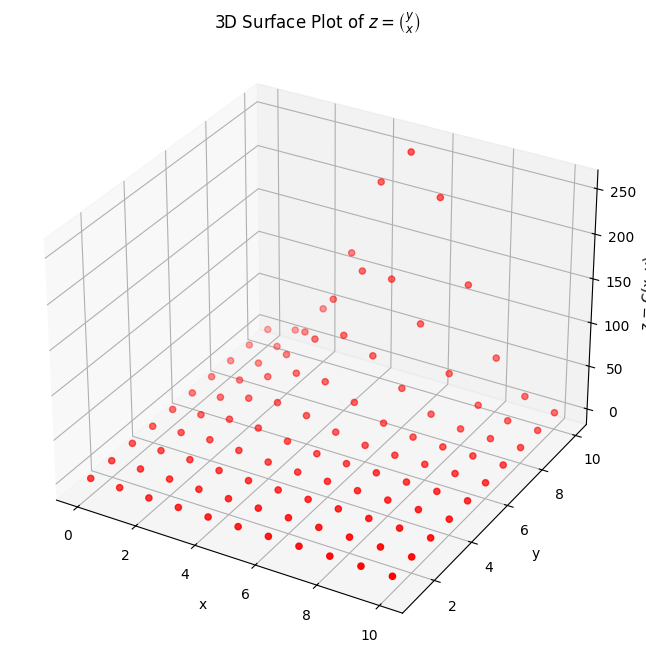

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb
from mpl_toolkits.mplot3d import Axes3D

# Define the range of x and y
y_values = np.arange(1, 11)
x_values = np.arange(0, 11)

# Create a meshgrid of x and y values
X, Y = np.meshgrid(x_values, y_values)

# Compute the binomial coefficient for each pair (x, y)
Z = comb(Y, X)

# Plotting the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Create the surface plot
# ax.plot_surface(X, Y, Z, cmap='viridis')

ax.scatter(X, Y, Z, c='r', marker='o')

# Labeling the axes
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z = C(x, y)')

# Title
ax.set_title(r'3D Surface Plot of $z = \binom{y}{x}$')

plt.show()
